# 4.4. Recorte en realizaciones y filtro de Wiener

Se evaluará un filtro de Wiener estimado a partir de latidos alineados
en el pico R. Cada segmento abarcará desde 250 ms antes hasta 400 ms
después del pico.

El filtro se aplicará al ECG continuo. El promedio de latidos se
utilizará para estimar el filtro, sin reemplazar los latidos individuales,
porque sus variaciones contienen información para calcular el EDR.

El análisis utilizará únicamente registros de desarrollo. La incorporación
del filtro dependerá de la comparación con el procesamiento vigente,
siguiendo el criterio establecido por el grupo.

In [1]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
from pathlib import Path
import os
import sys

ROOT = Path("/content/drive/MyDrive/TP-PSB-G8-main")

assert (ROOT / "src" / "config.py").exists(), "Revisá la ruta del proyecto."

os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

In [3]:
%pip install -q -r requirements.txt

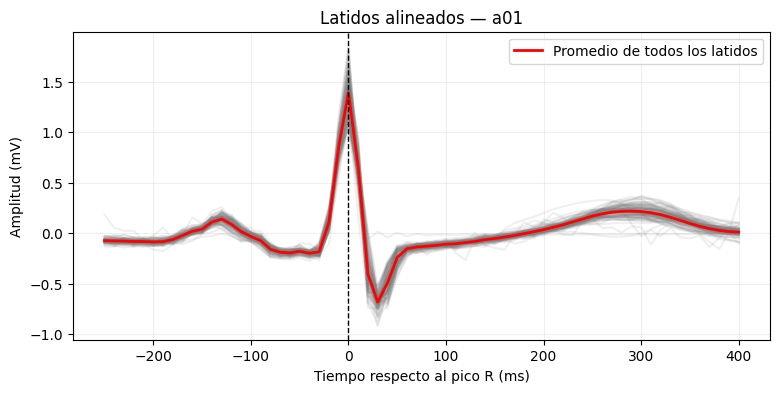

Frecuencia de muestreo: 100.0 Hz
Matriz de latidos: (29938, 66)


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import SPLIT_CSV, ECG_FILTER
from src.data import load_ecg, load_qrs
from src.preprocessing.filters import design_bandpass, apply_zero_phase
from src.features.edr import qrs_reference
from src.qrs.pan_tompkins import r_peaks_from_marks

# Usar un registro de desarrollo
registro = "a01"
split = pd.read_csv(SPLIT_CSV)
assert registro in split.loc[split["set"] == "dev", "record"].values

ecg, fs = load_ecg(registro)
marcas = load_qrs(registro)

# Mismo preprocesamiento que el pipeline vigente
ecg_filtrado = apply_zero_phase(
    ecg, design_bandpass(fs, *ECG_FILTER)
)

offset, signo = qrs_reference(ecg_filtrado, marcas, fs)

tiempos_r, _ = r_peaks_from_marks(
    ecg_filtrado, marcas, fs, offset, signo, refine=True
)

# Recortar desde −250 ms hasta +400 ms, alineando en R.
# Interpolar permite conservar la posición fraccionaria del pico refinado.
antes = int(round(0.250 * fs))
despues = int(round(0.400 * fs))
desplazamientos = np.arange(-antes, despues + 1)

centros = tiempos_r * fs
centros = centros[
    (centros - antes >= 0)
    & (centros + despues <= len(ecg_filtrado) - 1)
]

if len(centros) == 0:
    raise ValueError("No hay latidos con un recorte completo.")

posiciones = centros[:, None] + desplazamientos

latidos = np.interp(
    posiciones.ravel(),
    np.arange(len(ecg_filtrado)),
    ecg_filtrado
).reshape(posiciones.shape)

tiempo_ms = desplazamientos / fs * 1000
promedio = latidos.mean(axis=0)

# Mostrar una muestra de latidos y el promedio de todos
seleccion = np.linspace(
    0, len(latidos) - 1, min(100, len(latidos)), dtype=int
)

plt.figure(figsize=(9, 4))
plt.plot(
    tiempo_ms, latidos[seleccion].T,
    color="gray", alpha=0.12
)
plt.plot(
    tiempo_ms, promedio,
    color="red", linewidth=2, label="Promedio de todos los latidos"
)
plt.axvline(0, color="black", linestyle="--", linewidth=1)
plt.xlabel("Tiempo respecto al pico R (ms)")
plt.ylabel("Amplitud (mV)")
plt.title(f"Latidos alineados — {registro}")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

print("Frecuencia de muestreo:", fs, "Hz")
print("Matriz de latidos:", latidos.shape)

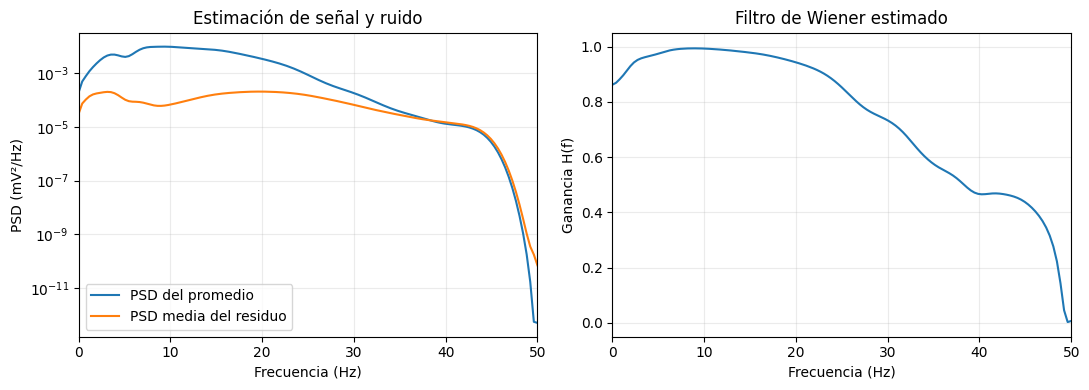

In [5]:
from scipy.signal import periodogram

# Separar el promedio y las diferencias respecto a él
promedio = latidos.mean(axis=0)
residuos = latidos - promedio

# Misma configuración espectral para señal y residuo.
# El relleno con ceros da una grilla más densa, sin aumentar
# la resolución real de los recortes.
opciones = dict(
    fs=fs,
    window="hann",
    detrend="constant",
    scaling="density",
    nfft=256
)

frecuencias, psd_senal = periodogram(promedio, **opciones)

_, psd_residuos = periodogram(
    residuos,
    axis=1,
    **opciones
)

psd_ruido = psd_residuos.mean(axis=0)

# Ganancia entre 0 y 1: cuánto conserva de cada frecuencia
denominador = psd_senal + psd_ruido

H = np.divide(
    psd_senal,
    denominador,
    out=np.zeros_like(psd_senal),
    where=denominador > 0
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].semilogy(
    frecuencias, np.maximum(psd_senal, 1e-20),
    label="PSD del promedio"
)
axes[0].semilogy(
    frecuencias, np.maximum(psd_ruido, 1e-20),
    label="PSD media del residuo"
)
axes[0].set_xlabel("Frecuencia (Hz)")
axes[0].set_ylabel("PSD (mV²/Hz)")
axes[0].set_title("Estimación de señal y ruido")
axes[0].legend()

axes[1].plot(frecuencias, H)
axes[1].set_xlabel("Frecuencia (Hz)")
axes[1].set_ylabel("Ganancia H(f)")
axes[1].set_ylim(-0.05, 1.05)
axes[1].set_title("Filtro de Wiener estimado")

for ax in axes:
    ax.set_xlim(0, fs / 2)
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

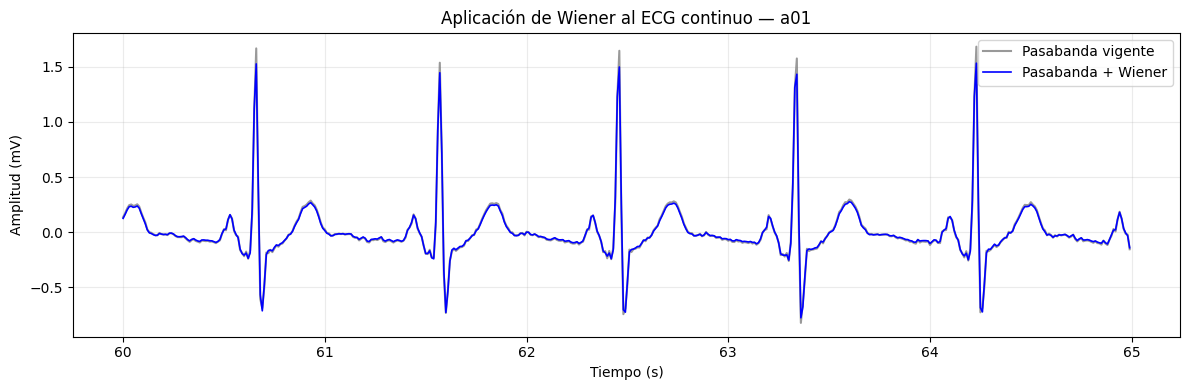

In [6]:
from scipy.signal import firwin2, fftconvolve

# Aproximación FIR de la ganancia estimada.
# La longitud queda fijada para esta implementación.
N_COEF = 129

coeficientes = firwin2(
    numtaps=N_COEF,
    freq=frecuencias,
    gain=H,
    fs=fs
)

# Extender por reflexión para reducir efectos de borde.
margen = (N_COEF - 1) // 2
extendido = np.pad(ecg_filtrado, margen, mode="reflect")

# "same" centra la convolución del FIR simétrico:
# compensa su retardo para la comparación fuera de línea.
salida = fftconvolve(extendido, coeficientes, mode="same")
ecg_wiener = salida[margen:-margen]

assert len(ecg_wiener) == len(ecg_filtrado)
assert np.isfinite(ecg_wiener).all()

# Comparar un tramo fijo de 5 segundos, sin normalizar amplitudes.
inicio_s, duracion_s = 60, 5
i = int(inicio_s * fs)
j = int((inicio_s + duracion_s) * fs)
tiempo = np.arange(i, j) / fs

plt.figure(figsize=(12, 4))
plt.plot(
    tiempo, ecg_filtrado[i:j],
    color="gray", alpha=0.8,
    label="Pasabanda vigente"
)
plt.plot(
    tiempo, ecg_wiener[i:j],
    color="blue", linewidth=1.2,
    label="Pasabanda + Wiener"
)
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud (mV)")
plt.title(f"Aplicación de Wiener al ECG continuo — {registro}")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [7]:
from src.features.edr import beat_matrix, edr_area
from src.qrs.rr_clean import rr_in_range

# Mismos centros y polaridad que el EDR del pipeline vigente
centros_edr = marcas + offset

beats_antes, ok_antes = beat_matrix(
    ecg_filtrado, centros_edr, fs, half_width=0.06
)
beats_despues, ok_despues = beat_matrix(
    ecg_wiener, centros_edr, fs, half_width=0.06
)

assert np.array_equal(ok_antes, ok_despues)

edr_antes = edr_area(beats_antes, signo, fs)
edr_despues = edr_area(beats_despues, signo, fs)

# Misma regla de intervalos RR válidos que el proyecto
validos = rr_in_range(centros_edr / fs)[ok_antes]
validos &= np.isfinite(edr_antes) & np.isfinite(edr_despues)

edr_antes = edr_antes[validos]
edr_despues = edr_despues[validos]

resumen_edr = pd.DataFrame({
    "Medida": ["Mediana (mV·s)", "Desvío estándar (mV·s)"],
    "Sin Wiener": [
        np.median(edr_antes),
        np.std(edr_antes, ddof=1)
    ],
    "Con Wiener": [
        np.median(edr_despues),
        np.std(edr_despues, ddof=1)
    ]
})

display(resumen_edr)

if edr_antes.std() > 0 and edr_despues.std() > 0:
    correlacion = np.corrcoef(edr_antes, edr_despues)[0, 1]
    print(f"Correlación entre ambos EDR: {correlacion:.4f}")
else:
    print("Correlación no calculable: alguna serie es constante.")

,Medida,Sin Wiener,Con Wiener
0,Mediana (mV·s),0.002291,0.002258
1,Desvío estándar (mV·s),0.004198,0.003915


Correlación entre ambos EDR: 0.9994


### Efecto inicial sobre el EDR

En el registro a01, el EDR antes y después de Wiener presentó una
correlación de 0,9994. La mediana disminuyó aproximadamente un 1,4 %
y el desvío estándar un 6,7 %.

El filtro conservó una variación temporal muy similar, aunque modificó
la escala del EDR. Esta comprobación es descriptiva y no determina
su incorporación al procesamiento.

In [8]:
%cd /content/drive/MyDrive/TP-PSB-G8-main

/content


In [9]:
%%writefile src/preprocessing/wiener.py
"""Wiener estimado a partir de latidos alineados en R.

El promedio de ensamble representa la señal y las diferencias respecto
al promedio representan el ruido estimado. Esas diferencias también
pueden contener variaciones fisiológicas.

El filtro se aplica al ECG continuo, sin reemplazar los latidos
individuales por el promedio.
"""

import numpy as np
from scipy.signal import periodogram, firwin2, fftconvolve


def extract_realizations(ecg, r_peaks, fs, pre=0.25, post=0.40):
    """Recorta latidos alrededor de R.

    r_peaks contiene posiciones en muestras, que pueden ser fraccionarias.
    Descarta los recortes incompletos e interpola para alinear los picos.
    Devuelve una matriz: filas = latidos, columnas = muestras.
    """
    x = np.asarray(ecg, dtype=float)
    peaks = np.asarray(r_peaks, dtype=float)

    if x.ndim != 1 or peaks.ndim != 1:
        raise ValueError("ECG y picos deben ser vectores.")
    if not np.isfinite(fs) or fs <= 0:
        raise ValueError("fs debe ser positiva.")
    if not np.isfinite([pre, post]).all() or pre < 0 or post < 0:
        raise ValueError("pre y post deben ser finitos y no negativos.")
    if len(x) == 0 or not np.isfinite(x).all():
        raise ValueError("El ECG debe ser no vacío y finito.")

    before = int(round(pre * fs))
    after = int(round(post * fs))
    offsets = np.arange(-before, after + 1)

    valid = (
        np.isfinite(peaks)
        & (peaks - before >= 0)
        & (peaks + after <= len(x) - 1)
    )
    centers = peaks[valid]

    if len(centers) == 0:
        return np.empty((0, len(offsets)))

    positions = centers[:, None] + offsets
    return np.interp(
        positions.ravel(), np.arange(len(x)), x
    ).reshape(positions.shape)


def estimate_psds(realizations, fs):
    """Devuelve frecuencias, PSD del promedio y PSD media del residuo."""
    beats = np.asarray(realizations, dtype=float)

    if beats.ndim != 2 or beats.shape[0] < 2 or beats.shape[1] < 2:
        raise ValueError("Se necesitan al menos dos latidos de dos muestras.")
    if not np.isfinite(beats).all():
        raise ValueError("Los latidos deben contener valores finitos.")
    if not np.isfinite(fs) or fs <= 0:
        raise ValueError("fs debe ser positiva.")

    template = beats.mean(axis=0)
    residuals = beats - template

    # Potencia de dos para incluir Nyquist y evitar truncar los recortes.
    # El relleno con ceros no aumenta la resolución espectral real.
    nfft = max(256, 1 << (beats.shape[1] - 1).bit_length())
    options = dict(
        fs=fs,
        window="hann",
        detrend="constant",
        scaling="density",
        nfft=nfft
    )

    f, s_s = periodogram(template, **options)
    _, residual_psds = periodogram(residuals, axis=1, **options)
    s_n = residual_psds.mean(axis=0)

    return f, s_s, s_n


def wiener_filter(ecg, f, s_s, s_n, fs):
    """Aplica una aproximación FIR de H = Ss / (Ss + Sn).

    Usa 129 coeficientes simétricos, extensión por reflexión y
    compensación del retardo. Es un procesamiento fuera de línea.
    """
    x = np.asarray(ecg, dtype=float)
    f = np.asarray(f, dtype=float)
    s_s = np.asarray(s_s, dtype=float)
    s_n = np.asarray(s_n, dtype=float)

    if not np.isfinite(fs) or fs <= 0:
        raise ValueError("fs debe ser positiva.")
    if x.ndim != 1 or len(x) < 2 or not np.isfinite(x).all():
        raise ValueError("El ECG debe ser un vector finito de al menos dos muestras.")
    if (
        f.ndim != 1 or len(f) < 2
        or s_s.shape != f.shape or s_n.shape != f.shape
    ):
        raise ValueError("Frecuencias y espectros deben ser vectores del mismo tamaño.")
    if not all(np.isfinite(v).all() for v in (f, s_s, s_n)):
        raise ValueError("Frecuencias y espectros deben ser finitos.")
    if (s_s < 0).any() or (s_n < 0).any():
        raise ValueError("Los espectros no pueden ser negativos.")
    if (
        f[0] != 0 or not np.isclose(f[-1], fs / 2)
        or (np.diff(f) <= 0).any()
    ):
        raise ValueError("Las frecuencias deben crecer desde 0 hasta fs/2.")

    total = s_s + s_n
    gain = np.divide(s_s, total, out=np.zeros_like(s_s), where=total > 0)

    # Asegurar extremos exactos para firwin2.
    frequencies = f.copy()
    frequencies[-1] = fs / 2

    coefficients = firwin2(129, frequencies, gain, fs=fs)

    margin = (len(coefficients) - 1) // 2
    padded = np.pad(x, margin, mode="reflect")
    filtered = fftconvolve(padded, coefficients, mode="same")

    return filtered[margin:-margin]

Overwriting src/preprocessing/wiener.py


In [10]:
import importlib
from src.preprocessing import wiener

importlib.reload(wiener)

latidos_modulo = wiener.extract_realizations(
    ecg_filtrado, tiempos_r * fs, fs
)

f_modulo, ss_modulo, sn_modulo = wiener.estimate_psds(
    latidos_modulo, fs
)

ecg_modulo = wiener.wiener_filter(
    ecg_filtrado, f_modulo, ss_modulo, sn_modulo, fs
)

# Verificar que trasladar el código al módulo no cambió los resultados.
np.testing.assert_allclose(latidos_modulo, latidos)
np.testing.assert_allclose(f_modulo, frecuencias)
np.testing.assert_allclose(ss_modulo, psd_senal)
np.testing.assert_allclose(sn_modulo, psd_ruido)
np.testing.assert_allclose(ecg_modulo, ecg_wiener)

print("Las funciones del módulo reproducen los resultados del notebook.")

Las funciones del módulo reproducen los resultados del notebook.


In [11]:
%%writefile tests/test_wiener.py
"""Pruebas con resultados conocidos para el bloque de Wiener."""

import numpy as np

from src.preprocessing.wiener import (
    extract_realizations,
    estimate_psds,
    wiener_filter
)


def test_recorte_fraccionario_y_bordes():
    # En una rampa, interpolar en una posición fraccionaria
    # debe devolver exactamente el valor de esa posición.
    ecg = np.arange(20, dtype=float)

    beats = extract_realizations(
        ecg,
        r_peaks=np.array([0, 5.5, 19]),
        fs=10,
        pre=0.2,
        post=0.3
    )

    # Los centros de los extremos no permiten un recorte completo.
    esperado = np.array([[3.5, 4.5, 5.5, 6.5, 7.5, 8.5]])
    np.testing.assert_allclose(beats, esperado)


def test_latidos_identicos_sin_residuo():
    fs = 100
    t = np.arange(100) / fs
    beat = np.sin(2 * np.pi * 10 * t)
    beats = np.tile(beat, (5, 1))

    f, s_s, s_n = estimate_psds(beats, fs)

    # Sin diferencias entre latidos, el residuo debe ser nulo.
    np.testing.assert_allclose(s_n, 0, atol=1e-25)

    # La señal conocida tiene su máximo espectral cerca de 10 Hz.
    assert abs(f[np.argmax(s_s)] - 10) < 0.5


def test_ganancia_unidad_conserva_senal():
    fs = 100
    x = np.random.default_rng(2026).normal(size=2000)
    f = np.linspace(0, fs / 2, 129)

    # Señal positiva y ruido nulo: la ganancia objetivo es 1.
    y = wiener_filter(x, f, np.ones_like(f), np.zeros_like(f), fs)

    assert y.shape == x.shape
    np.testing.assert_allclose(y, x, atol=1e-12, rtol=1e-12)


def test_atenua_componente_con_ruido_estimado():
    fs = 100
    t = np.arange(2000) / fs
    lenta = np.sin(2 * np.pi * 5 * t)
    rapida = np.sin(2 * np.pi * 20 * t)

    f = np.linspace(0, fs / 2, 257)

    # Modelo conocido: conservar hasta 8 Hz y rechazar desde 12 Hz.
    ganancia = np.interp(f, [0, 8, 12, 50], [1, 1, 0, 0])
    s_s = ganancia
    s_n = 1 - ganancia

    salida_lenta = wiener_filter(lenta, f, s_s, s_n, fs)
    salida_rapida = wiener_filter(rapida, f, s_s, s_n, fs)

    # Medir lejos de los bordes.
    interior = slice(200, -200)

    assert np.std(salida_lenta[interior]) > 0.9 * np.std(lenta[interior])
    assert np.std(salida_rapida[interior]) < 0.1 * np.std(rapida[interior])

Writing tests/test_wiener.py


In [12]:
!python -m pytest -q

.................sss.............................................x...... [ 84%]
........s....                                                            [100%]
80 passed, 4 skipped, 1 xfailed in 64.48s (0:01:04)


## Evaluación de Wiener en desarrollo

Se comparará F con y sin Wiener, manteniendo su configuración:
EDR por área del QRS, ventana de 240 s, Welch con tres segmentos
y banda de 0,01–0,05 Hz.

Se conserva el RR del procesamiento vigente para evaluar el efecto
de Wiener sobre el camino del EDR. Se compararán los mismos minutos
válidos y se utilizará el criterio de no inferioridad del grupo,
con margen de 0,02 en AUC y correlación por registro.

In [15]:
from src.config import RESULTS_DIR
from src.features.build import record_series, record_minute_table
from src.features.coupling import resample_uniform
from src.preprocessing import wiener

BANDA_F = {"ap": (0.01, 0.05)}

def comparar_wiener_registro(rec):
    # Referencia: procesamiento vigente, sin Wiener
    referencia = record_series(rec, edr_method="area")

    x, fs_rec = load_ecg(rec)
    qrs = load_qrs(rec)

    x = apply_zero_phase(
        x, design_bandpass(fs_rec, *ECG_FILTER)
    )

    off, sign = qrs_reference(x, qrs, fs_rec)
    t_r, _ = r_peaks_from_marks(x, qrs, fs_rec, off, sign)

    # Estimar y aplicar Wiener a esta noche
    beats = wiener.extract_realizations(x, t_r * fs_rec, fs_rec)
    f, ss, sn = wiener.estimate_psds(beats, fs_rec)
    x_w = wiener.wiener_filter(x, f, ss, sn, fs_rec)

    # EDR con los mismos centros y polaridad de la referencia
    centers = qrs + off
    beats_w, ok = beat_matrix(x_w, centers, fs_rec, half_width=0.06)
    area_w = edr_area(beats_w, sign, fs_rec)

    valid = rr_in_range(centers / fs_rec)[ok]
    valid &= np.isfinite(area_w)

    t_edr, edr_w = resample_uniform(
        centers[ok][valid] / fs_rec,
        area_w[valid],
        referencia["fs"]
    )

    # Alinear exactamente con la grilla de referencia
    keep = (
        (t_edr >= referencia["t"][0])
        & (t_edr <= referencia["t"][-1])
    )
    np.testing.assert_allclose(t_edr[keep], referencia["t"])

    con_wiener = dict(referencia)
    con_wiener["edr"] = edr_w[keep]
    con_wiener["edrs"] = {"area": edr_w[keep]}

    # Misma función de cálculo de F para las dos versiones
    tablas = {}

    for nombre, series in [
        ("F_sin", referencia),
        ("F_con", con_wiener)
    ]:
        tabla = record_minute_table(
            rec,
            width_s=240,
            bands=BANDA_F,
            series=series,
            edr_method="area",
            estimator="welch3"
        )

        tabla[nombre] = np.log(
            np.maximum(tabla["xp_ap"], 1e-12)
        )
        tablas[nombre] = tabla

    resultado = tablas["F_sin"][
        ["record", "minute", "label", "corrected", "F_sin"]
    ].merge(
        tablas["F_con"][["record", "minute", "F_con"]],
        on=["record", "minute"],
        how="outer",
        validate="one_to_one"
    )

    return resultado

In [16]:
import time

dev = split.loc[split["set"] == "dev", "record"].tolist()

CACHE_W = RESULTS_DIR / "wiener" / "fir129_v1"
CACHE_W.mkdir(parents=True, exist_ok=True)

inicio = time.time()

for numero, rec in enumerate(dev, start=1):
    ruta = CACHE_W / f"{rec}.parquet"

    if ruta.exists():
        print(f"[{numero}/{len(dev)}] {rec}: ya guardado", flush=True)
        continue

    print(f"[{numero}/{len(dev)}] {rec}: procesando...", flush=True)

    tabla = comparar_wiener_registro(rec)
    tabla.to_parquet(ruta, index=False)

    print("  Guardado.", flush=True)

evaluacion_wiener = pd.concat(
    [pd.read_parquet(CACHE_W / f"{rec}.parquet") for rec in dev],
    ignore_index=True
)

print(f"\nTiempo: {(time.time() - inicio) / 60:.1f} minutos")
print("Registros:", evaluacion_wiener["record"].nunique())
display(evaluacion_wiener.head())

[1/47] a01: procesando...
  Guardado.
[2/47] a02: procesando...
  Guardado.
[3/47] a03: procesando...
  Guardado.
[4/47] a04: procesando...
  Guardado.
[5/47] a05: procesando...
  Guardado.
[6/47] a08: procesando...
  Guardado.
[7/47] a09: procesando...
  Guardado.
[8/47] a10: procesando...
  Guardado.
[9/47] a12: procesando...
  Guardado.
[10/47] a13: procesando...
  Guardado.
[11/47] a14: procesando...
  Guardado.
[12/47] a15: procesando...
  Guardado.
[13/47] a17: procesando...
  Guardado.
[14/47] a18: procesando...
  Guardado.
[15/47] a19: procesando...
  Guardado.
[16/47] a20: procesando...
  Guardado.
[17/47] b01: procesando...
  Guardado.
[18/47] b02: procesando...
  Guardado.
[19/47] b03: procesando...
  Guardado.
[20/47] c01: procesando...
  Guardado.
[21/47] c02: procesando...
  Guardado.
[22/47] c03: procesando...
  Guardado.
[23/47] c06: procesando...
  Guardado.
[24/47] c07: procesando...
  Guardado.
[25/47] c09: procesando...
  Guardado.
[26/47] c10: procesando...
  Guard

,record,minute,label,corrected,F_sin,F_con
0,a01,2,0,0.013514,-6.639947,-6.733558
1,a01,3,0,0.000000,-6.628961,-6.723207
2,a01,4,0,0.000000,-6.744122,-6.825954
3,a01,5,0,0.000000,-7.735282,-7.801814
4,a01,6,0,0.000000,-7.153982,-7.219838


In [17]:
from src.features.variants import coupling_variants, hrv_variants
from src.stats.compare import compare_variants, agreement_compare

CACHE_E3 = RESULTS_DIR / "e3"

coup_base = pd.read_parquet(CACHE_E3 / "acoplamiento.parquet")
hrv_base = pd.read_parquet(CACHE_E3 / "hrv.parquet")

wide_c, _ = coupling_variants(coup_base)
wide_h, _ = hrv_variants(hrv_base)

info = (
    coup_base.loc[
        (coup_base["edr"] == "area")
        & (coup_base["window"] == 512)
        & (coup_base["estimator"] == "welch3")
    ]
    .set_index(["record", "minute"])[["label", "corrected"]]
)

# Misma selección de minutos del notebook 04
idx = (
    wide_c.dropna().index
    .intersection(wide_h.dropna().index)
    .intersection(
        info.index[
            (info["label"] >= 0)
            & (info["corrected"] <= 0.20)
        ]
    )
)

comparacion_w = (
    evaluacion_wiener
    .set_index(["record", "minute"])
    .reindex(idx)
)

validos = np.isfinite(
    comparacion_w[["F_sin", "F_con"]]
).all(axis=1)

print("Minutos previstos:", len(idx))
print("Sin ambas versiones de F:", int((~validos).sum()))

comparacion_w = comparacion_w.loc[validos]
idx_eval = comparacion_w.index

# Comprobar que la referencia coincide con la F ya calculada
nombre_f = "area|240s|welch3|apnea|potencia sola"

np.testing.assert_allclose(
    comparacion_w["F_sin"],
    wide_c.loc[idx_eval, nombre_f],
    rtol=1e-8,
    atol=1e-10
)

F_eval = comparacion_w[["F_sin", "F_con"]]
y_eval = info.loc[idx_eval, "label"].to_numpy(dtype=int)
registros_eval = idx_eval.get_level_values("record").to_numpy()

sujetos_eval = (
    split.set_index("record")
    .loc[registros_eval, "subject"]
    .to_numpy()
)

print("Minutos evaluados:", len(F_eval))
print("Registros:", len(np.unique(registros_eval)))
print("Sujetos:", len(np.unique(sujetos_eval)))
print("La F sin Wiener reproduce la referencia.")

# Liberar las tablas grandes que ya no necesitamos
del coup_base, hrv_base, wide_c, wide_h

Minutos previstos: 22125
Sin ambas versiones de F: 0
Minutos evaluados: 22125
Registros: 47
Sujetos: 19
La F sin Wiener reproduce la referencia.


In [18]:
resultado_auc = compare_variants(
    F_eval, y_eval, sujetos_eval,
    n_boot=2000, seed=2026
)

resultado_registro = agreement_compare(
    F_eval, y_eval, registros_eval, sujetos_eval,
    n_boot=2000, seed=2026
)

def resumir_diferencia(tabla, medida):
    """Expresar siempre la diferencia como con Wiener − sin Wiener."""
    diferencia = (
        tabla.loc["F_con", medida]
        - tabla.loc["F_sin", medida]
    )

    # Las funciones del grupo expresan los IC respecto a la mejor versión.
    if tabla.loc["F_sin", medida] >= tabla.loc["F_con", medida]:
        inferior = tabla.loc["F_con", "dif_lo"]
        superior = tabla.loc["F_con", "dif_hi"]
    else:
        inferior = -tabla.loc["F_sin", "dif_hi"]
        superior = -tabla.loc["F_sin", "dif_lo"]

    return {
        "Sin Wiener": tabla.loc["F_sin", medida],
        "Con Wiener": tabla.loc["F_con", medida],
        "Diferencia": diferencia,
        "IC95 inferior": inferior,
        "IC95 superior": superior
    }

criterio_wiener = pd.DataFrame({
    "AUC por minuto": resumir_diferencia(resultado_auc, "auc"),
    "Spearman por registro": resumir_diferencia(
        resultado_registro, "spearman"
    )
}).T

criterio_wiener["Cumple no inferioridad"] = (
    criterio_wiener["IC95 inferior"] >= -0.02
)

display(criterio_wiener.round(4))

,Sin Wiener,Con Wiener,Diferencia,IC95 inferior,IC95 superior,Cumple no inferioridad
AUC por minuto,0.8747,0.8788,0.0041,-0.0093,0.0167,True
Spearman por registro,0.8104,0.7633,-0.0471,-0.1649,0.0380,False


### Evaluación del criterio de incorporación

Wiener cumplió el criterio de no inferioridad en AUC por minuto:
la diferencia fue +0,0041, con IC95 % de −0,0093 a +0,0167.

Sin embargo, no lo cumplió en la correlación de Spearman por registro.
La diferencia fue −0,0471, con IC95 % de −0,1649 a +0,0380.
Su límite inferior quedó por debajo del margen permitido de −0,02.

Como el criterio exige cumplir ambas medidas, se mantiene el
procesamiento sin Wiener. El filtro queda implementado y evaluado,
pero no se incorpora al pipeline vigente.

No cumplir no inferioridad no demuestra que Wiener sea peor:
indica que los datos no permiten descartar una pérdida mayor
que el margen establecido.

### Control con respiración real

Se compara la coherencia entre el EDR y las señales respiratorias
medidas en los ocho registros disponibles, antes y después de Wiener.
Se reutiliza la métrica de validación del proyecto.

Este control describe el efecto sobre el EDR y no modifica el criterio
de incorporación del filtro.

In [19]:
from src.config import RESP_RECORDS
from src.data import load_respiration
from src.features.edr import validate_edr
from src.features.coupling import downsample

assert set(RESP_RECORDS).issubset(set(dev))

filas_control = []

for numero, rec in enumerate(RESP_RECORDS, start=1):
    print(f"[{numero}/{len(RESP_RECORDS)}] {rec}", flush=True)

    ecg_rec, fs_rec = load_ecg(rec)
    qrs_rec = load_qrs(rec)

    x = apply_zero_phase(
        ecg_rec, design_bandpass(fs_rec, *ECG_FILTER)
    )

    off, sign = qrs_reference(x, qrs_rec, fs_rec)
    t_r, _ = r_peaks_from_marks(x, qrs_rec, fs_rec, off, sign)

    realizaciones = wiener.extract_realizations(
        x, t_r * fs_rec, fs_rec
    )
    f, ss, sn = wiener.estimate_psds(realizaciones, fs_rec)
    x_w = wiener.wiener_filter(x, f, ss, sn, fs_rec)

    # Mismos centros y latidos para ambas versiones del EDR
    centers = qrs_rec + off
    beats_sin, ok = beat_matrix(x, centers, fs_rec, 0.06)
    beats_con, ok_con = beat_matrix(x_w, centers, fs_rec, 0.06)

    assert np.array_equal(ok, ok_con)

    valores_sin = edr_area(beats_sin, sign, fs_rec)
    valores_con = edr_area(beats_con, sign, fs_rec)

    valid = rr_in_range(centers / fs_rec)[ok]
    valid &= np.isfinite(valores_sin) & np.isfinite(valores_con)
    tiempos = centers[ok][valid] / fs_rec

    # Respiración medida, remuestreada a 2 Hz
    respiracion, fs_resp = load_respiration(rec)
    canales = {
        canal: downsample(respiracion[canal], fs_resp, 2.0)
        for canal in ["Resp C", "Resp A", "Resp N"]
    }

    fila = {"Registro": rec}

    for nombre, valores in [
        ("Sin Wiener", valores_sin),
        ("Con Wiener", valores_con)
    ]:
        tu, vu = resample_uniform(tiempos, valores[valid], 2.0)
        posiciones = np.rint(tu * 2).astype(int)

        coherencias = []

        for canal in canales.values():
            dentro = (posiciones >= 0) & (posiciones < len(canal))

            resultados = validate_edr(
                vu[dentro],
                canal[posiciones[dentro]],
                fs=2.0
            )

            finitos = resultados[np.isfinite(resultados)]
            coherencias.append(
                np.median(finitos) if len(finitos) else np.nan
            )

        fila[nombre] = np.mean(coherencias)

    filas_control.append(fila)

control_resp = pd.DataFrame(filas_control).set_index("Registro")
control_resp["Diferencia"] = (
    control_resp["Con Wiener"] - control_resp["Sin Wiener"]
)

display(control_resp.round(4))

print("Promedio entre registros:")
display(control_resp.mean().to_frame("Media").round(4))

[1/8] a01
[2/8] a02
[3/8] a03
[4/8] a04
[5/8] b01
[6/8] c01
[7/8] c02
[8/8] c03


,Sin Wiener,Con Wiener,Diferencia
Registro,,,
a01,0.5123,0.5149,0.0026
a02,0.3390,0.3415,0.0025
a03,0.4571,0.4575,0.0004
a04,0.3210,0.3236,0.0026
b01,0.6298,0.6606,0.0308
c01,0.6308,0.6921,0.0613
c02,0.5223,0.5194,-0.0030
c03,0.7513,0.7645,0.0132


Promedio entre registros:


,Media
Sin Wiener,0.5205
Con Wiener,0.5343
Diferencia,0.0138


### Control con respiración real y conclusión

La coherencia media entre el EDR y la respiración medida pasó de
0,5205 sin Wiener a 0,5343 con Wiener, una diferencia de +0,0138.
Aumentó en siete de los ocho registros y disminuyó ligeramente en c02.
El resultado es descriptivo y no demuestra una mejora estadísticamente
significativa.

Wiener cumplió no inferioridad en AUC por minuto, pero no en Spearman
por registro. Como el criterio del grupo exige cumplir ambas medidas,
se mantiene el procesamiento sin Wiener.

El bloque queda implementado, con pruebas de funcionamiento,
evaluación en desarrollo y control contra respiración real.